# FP-Growth: Khai thác tập phổ biến (Group 23)
Notebook demo: chạy lại toàn bộ thực nghiệm và hai ứng dụng bằng cài đặt FP-Growth của nhóm.

In [1]:
import os, sys

# Trên Colab: tải repo về. Chạy ở máy thì bỏ qua bước này.
if "google.colab" in sys.modules and not os.path.exists("Frequent_Itemset"):
    !git clone -q https://github.com/KhoaTranFitus/Frequent_Itemset.git

if os.path.exists("Frequent_Itemset"):
    os.chdir("Frequent_Itemset")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # chạy ở máy, notebook nằm trong notebooks/

sys.path.insert(0, os.getcwd())          # để import được src/ và scripts/
!pip install -q -r requirements.txt
print("Thư mục làm việc:", os.getcwd())

Thư mục làm việc: d:\datamining\Group_23


## 4. Ứng dụng 2: Khai thác mẫu trong dữ liệu DNA

**Dữ liệu:** UCI Splice-junction Gene Sequences, gồm 3190 chuỗi DNA dài 60 nucleotide,
được gán nhãn EI (donor, ranh giới exon→intron), IE (acceptor, ranh giới intron→exon) hoặc N (không có ranh giới).

**Biến chuỗi thành giao dịch:** mỗi chuỗi là một giao dịch; mỗi item có dạng `P<vị trí>=<nucleotide>`,
với vị trí tính từ −30 đến +30 so với ranh giới (không có vị trí 0). Ví dụ: `P+1=G` là "G ở vị trí ngay sau ranh giới".
Vị trí phải ghép vào item, vì nếu chỉ lấy {A, C, G, T} thì chuỗi nào cũng chứa đủ 4 chữ.

In [2]:
from src.app2_bio import read_splice, to_transaction, load_groups

DATA_PATH = "data/app2/splice.data"
rows = read_splice(DATA_PATH)
label, seq = rows[0]
t = to_transaction(seq)
print(f"Mẫu đầu tiên ({label}): {seq}")
print(f"Giao dịch: {len(t)} item, quanh ranh giới: {t[27:33]}")

groups, code = load_groups(DATA_PATH)
print(f"{len(code)} item khác nhau | " + ", ".join(f"{k}: {len(v)} mẫu" for k, v in groups.items()))

Mẫu đầu tiên (EI): CCAGCTGCATCACAGGAGGCCAGCGAGCAGGTCTGTTCCAAGGGCCTTCGAGCCAGTCTG
Giao dịch: 60 item, quanh ranh giới: ['P-3=C', 'P-2=A', 'P-1=G', 'P+1=G', 'P+2=T', 'P+3=C']
240 item khác nhau | EI: 767 mẫu, IE: 768 mẫu, N: 1655 mẫu


### Chọn minsup
Mỗi vị trí có 4 khả năng, nên nếu DNA ngẫu nhiên thì mỗi item có support khoảng 25%.
Chạy FP-Growth riêng từng nhóm ở nhiều mức minsup để chọn mức chỉ giữ lại tín hiệu mạnh.

In [3]:
import pandas as pd
from src.algorithm.fpgrowth import fpgrowth
from src.config import to_min_count

table = {}
for minsup in [0.3, 0.5, 0.7]:
    table[minsup] = {label: len(fpgrowth(data, to_min_count(minsup, len(data))))
                     for label, data in groups.items()}
pd.DataFrame(table).T.rename_axis("minsup")

,EI,IE,N
minsup,,,
0.3,280,331,0
0.5,35,7,0
0.7,15,7,0


In [4]:
from src.utils import decode

for label in ["EI", "IE"]:
    data = groups[label]
    named = decode(fpgrowth(data, to_min_count(0.5, len(data))), code)
    top = sorted(named.items(), key=lambda x: x[1], reverse=True)[:7]
    print(f"\nTop của {label}:")
    for itemset, sup in top:
        print(f"  {sup / len(data):6.1%}  {itemset}")


Top của EI:
   99.7%  ('P+1=G',)
   99.0%  ('P+2=T',)
   99.0%  ('P+1=G', 'P+2=T')
   85.7%  ('P+5=G',)
   85.5%  ('P+1=G', 'P+5=G')
   85.0%  ('P+2=T', 'P+5=G')
   85.0%  ('P+1=G', 'P+2=T', 'P+5=G')

Top của IE:
   99.7%  ('P-1=G',)
   99.6%  ('P-2=A',)
   99.5%  ('P-1=G', 'P-2=A')
   78.9%  ('P-3=C',)
   78.9%  ('P-1=G', 'P-3=C')
   78.8%  ('P-2=A', 'P-3=C')
   78.8%  ('P-1=G', 'P-2=A', 'P-3=C')


In [5]:
from scripts.app2_check import show_exceptions
from src.app2_bio import read_splice_with_name

rows_named = read_splice_with_name(DATA_PATH)
show_exceptions(rows_named, "EI", 30, "GT")
show_exceptions(rows_named, "IE", 28, "AG")


EI: 8/767 mẫu không có GT
  thay vào đó là: Counter({'GC': 4, 'NN': 1, 'GG': 1, 'GA': 1, 'CA': 1})
  HUMALPI1-DONOR-42         NNNNN|NNNNN
  HUMAPRTA-DONOR-881        CGCAG|GCGAG
  HUMFVII-DONOR-70          TGCAG|GCGGG
  HUMINCPPS-DONOR-940       GCAGG|GGCCA
  HUMINCPPS-DONOR-2825      TGAGG|GAGTA
  HUMKER18-DONOR-4285       AAGAG|GCAAG
  HUMMYC3L-DONOR-2594       CTCTA|CAACG
  HUMTHB-DONOR-10723        TGCTG|GCAAG

IE: 4/768 mẫu không có AG
  thay vào đó là: Counter({'AC': 1, 'TG': 1, 'GG': 1, 'CA': 1})
  HUMAK1-ACCEPTOR-3918      CTTAC|AGAGC
  HUMAK1-ACCEPTOR-10488     CGCTG|AGGGC
  HUMALPI1-ACCEPTOR-124     CCTGG|CCAGC
  HUMINCPPS-ACCEPTOR-2712   ATACA|TGTAT


In [6]:
from scripts.app2_emerging import emerging
from src.utils import invert_code

name_of = invert_code(code)
for label in ["EI", "IE"]:
    rows_e = emerging(groups[label], groups["N"], 0.5)
    rows_e.sort(key=lambda r: (r[3], r[1]), reverse=True)
    df = pd.DataFrame([{"itemset": ", ".join(name_of[i] for i in r[0]),
                        label: f"{r[1]:.1%}", "N": f"{r[2]:.1%}",
                        "#N": r[4], "growth": round(r[3], 1)} for r in rows_e[:8]])
    display(df)

,itemset,EI,N,#N,growth
0,"P+1=G, P+2=T, P+4=A, P+5=G",63.8%,0.1%,1,1055.1
1,"P+1=G, P+2=T, P+5=G, P-1=G",67.1%,0.1%,2,555.6
2,"P+1=G, P+2=T, P+4=A, P-1=G",55.0%,0.2%,3,303.5
3,"P+1=G, P+2=T, P-1=G, P-2=A",50.3%,0.5%,8,104.1
4,"P+1=G, P+2=T, P+5=G",85.0%,0.9%,15,93.8
5,"P+2=T, P+5=G, P-1=G",67.1%,1.1%,18,61.7
6,"P+1=G, P+2=T, P+4=A",71.7%,1.2%,20,59.3
7,"P+2=T, P+4=A, P-1=G",55.0%,1.0%,17,53.6


,itemset,IE,N,#N,growth
0,"P-1=G, P-2=A, P-3=C",78.8%,2.3%,38,34.3
1,"P-1=G, P-2=A",99.5%,7.7%,127,13.0
2,"P-2=A, P-3=C",78.8%,6.1%,101,12.9
3,"P-1=G, P-3=C",78.9%,7.4%,123,10.6
4,P-2=A,99.6%,24.2%,400,4.1
5,P-1=G,99.7%,26.0%,431,3.8
6,P-3=C,78.9%,25.0%,413,3.2


Đã lưu docs/figures/app2_profile.png
Đã lưu docs/figures/app2_emerging.png


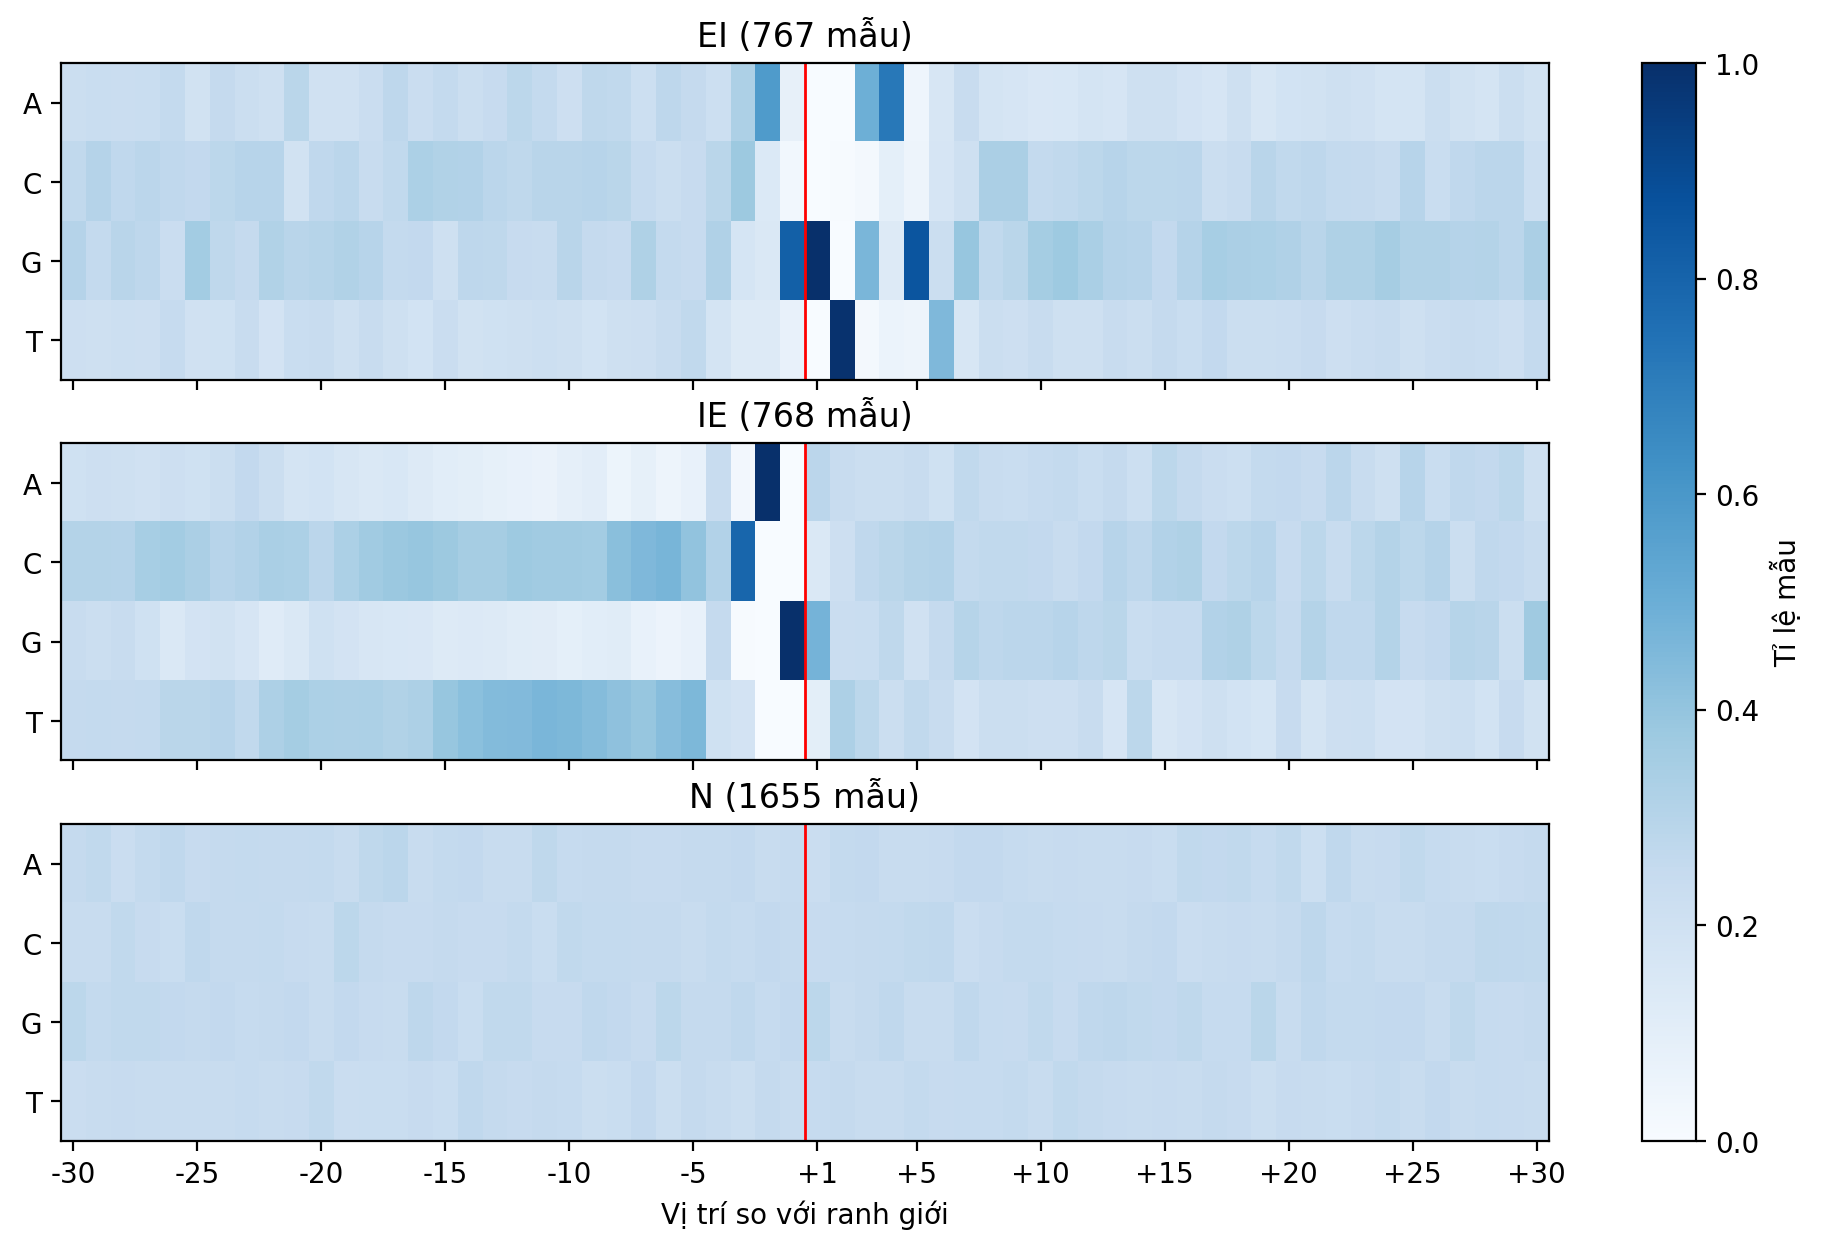

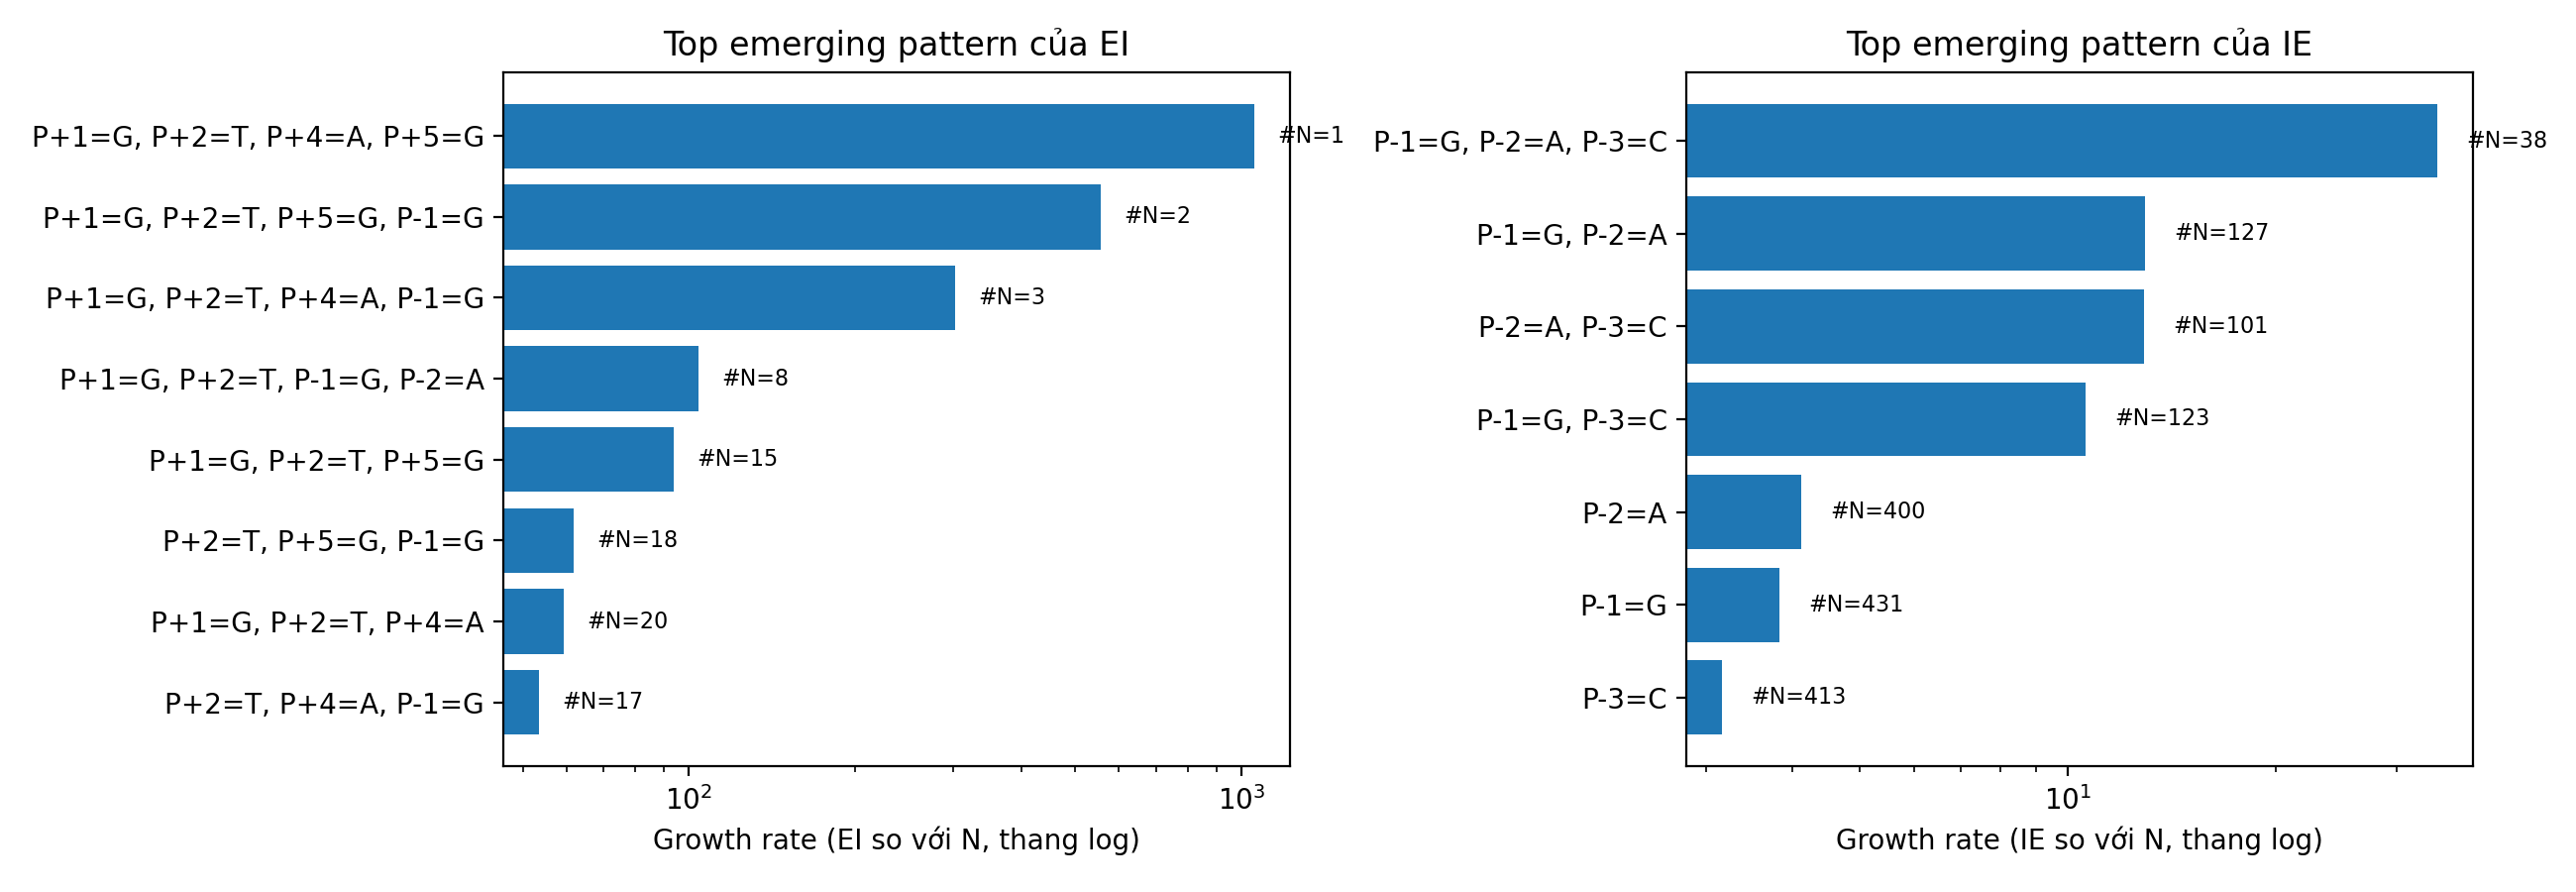

In [7]:
from IPython.display import Image
from scripts.app2_plot import plot_profile, plot_emerging

os.makedirs("docs/figures", exist_ok=True)
plot_profile(rows)
plot_emerging(groups, code)
display(Image("docs/figures/app2_profile.png", width=900))
display(Image("docs/figures/app2_emerging.png", width=900))

### Nhận xét
- FP-Growth tự tìm ra quy tắc GT–AG: {P+1=G, P+2=T} có trong 99.0% mẫu EI, {P-2=A, P-1=G} trong 99.5% mẫu IE.
- Nhóm N không có itemset nào ở minsup 0.3, đúng là nhóm đối chứng.
- ...